# LSTM-VAE latent spaces on the Nature data

A recurrent VAE with the conv VAE's latent, so every score and view of notebooks 02 and 05 applies unchanged
(`ml/common/models/seq_vae.py`, `LSTMVAE`; trainer `ml/nature/awareness/train_vae.py --arch lstm`).

| part | layout |
|---|---|
| encoder | 2-layer LSTM over the window's samples (hidden 64), its outputs averaged over 8 equal segments, 1x1 heads to the mean and log variance: 4 filters x 8 steps, as the conv VAE |
| decoder | non-autoregressive: the latent interpolated back to every sample, a 2-layer LSTM (hidden 64), a linear map to the channels; it has no path to the window but the latent, so the KL stays well above zero at β 1 and 32 (Bowman et al. 2016), though β 128 still collapses it on raw input (section 8) |
| size | 107 to 109 k parameters, by channel count (conv VAE 30 to 34 k, Transformer VAE 217 to 251 k) |
| training | as the conv VAE (AE settings, early stopping on the validation negative ELBO), in fp32 (cuDNN's LSTM) |

**Why it might help**: the LSTM reads the window in time order and its decoder rebuilds it sample by sample, so its
reconstruction error and likelihood are per sample and could flag a change part-way through a window (Park, Hoshi and
Kemp 2018). Its encoder is causal within the window.

**Runs**: the four inputs of the ablation (1 s raw, 1 s + spectral, 3 s raw, 3 s + spectral) x the cells that mattered in
the conv grid (β 1, 32, 128 with fixed decoder variance; β 1 with the learned one) x three seeds: 48 runs,
`submit.sh --vae --inputs <input> --args "--arch lstm" --array 0-11`, pulled to `runs/vae/lstm_vae_*`. Every view uses
the four validation participants; scores are notebook 05's.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature', 'notebooks/nature/model_exploration/onboard'):   # shared code, Nature data, helpers
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import nature_data as nt
import _latent_views as lv
import _vae_runs as vr
import _novelty_scores as ns

ARCH, MODEL_PREFIX, TAG, NB = 'lstm', 'LSTM-VAE ·', 'lstm_vae', '03'   # architecture shown here and figure prefix (02 conv, 03 LSTM, 04 Transformer)
RUNS = Path(os.environ.get('HIPEXO_VAE_RUNS', REPO / 'notebooks' / 'nature' / 'model_exploration' / 'runs' / 'vae'))
DATA = REPO / 'data' / 'processed_nature' / 'ae'                              # built by ml/nature/awareness/ae_data.py
VIEW_CACHE = REPO / 'data' / 'cache' / 'nature' / 'vae_views'
SHOWN_SEED = 0
FIG_DIR = Path.cwd() / 'figures'                                            # figures for Live_Update
FIG_DIR.mkdir(exist_ok = True)
pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

meta = json.loads((DATA / 'meta.json').read_text())
tables = {inputs: pd.read_parquet(DATA / spec['table']) for inputs, spec in meta['inputs'].items()}
found = vr.discover_vae_runs(RUNS, ARCH)
HAVE_RUNS = not found.empty
if HAVE_RUNS:
    runs = {r.run: vr.load_vae_run(r.run, tables[r.inputs]) for r in found.itertuples()}
    print(f'{len(found)} runs in {found.groupby(vr.CELL_COLS).ngroups} cells under {RUNS}; '
          f'code {sorted({r["summary"]["git_sha"] for r in runs.values()})}')
    display(found.pivot_table(index = ['inputs', 'decoder_variance'], columns = 'beta', values = 'seed', aggfunc = 'count').fillna(0).astype(int))
else:
    print(f'No finished {ARCH} VAE runs under {RUNS} yet. Run the grid on the cluster and pull it (commands above), then rerun.')

48 runs in 16 cells under /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/notebooks/nature/model_exploration/runs/vae; code ['248e43c-dirty']


beta                              1.0    32.0   128.0
inputs          decoder_variance                     
raw_1s          fixed                 3      3      3
                learned               3      0      0
raw_1s_spectral fixed                 3      3      3
                learned               3      0      0
raw_3s          fixed                 3      3      3
                learned               3      0      0
raw_3s_spectral fixed                 3      3      3
                learned               3      0      0

## 1. What was trained

Validation participants, familiar windows for training and early stopping; NLL and KL are per window (summed over its
channels and samples, 16 × 200 on 1 s raw input, 23 channels with the spectral features and 600 samples at 3 s, and
over the 32 latent dimensions). A dimension is *active* when its median posterior
variance on the familiar validation windows is below 0.9 (the Science Robotics study's definition).

In [2]:
if HAVE_RUNS:
    cells, per_seed = vr.get_cell_table(runs, found)
    display(cells)
    display(per_seed.round(4))

seeds best epoch val NLL / window val KL / window          val MSE active dims (of 32)    minutes
inputs          decoder_variance beta                                                                                                    
raw_1s          fixed            1.0        3     21 ± 6     3392.2 ± 3.2    56.13 ± 0.57  0.2822 ± 0.0020          24.0 ± 0.0  1.4 ± 0.2
                                 32.0       3    22 ± 12    3664.3 ± 19.8     6.00 ± 0.09  0.4523 ± 0.0124           8.0 ± 0.0  1.4 ± 0.5
                                 128.0      3      1 ± 1     4415.0 ± 8.0     0.00 ± 0.00  0.9215 ± 0.0050           0.0 ± 0.0  0.5 ± 0.0
                learned          1.0        3     37 ± 6    1623.1 ± 25.7   117.45 ± 2.15  0.2818 ± 0.0044          32.0 ± 0.0  2.0 ± 0.2
raw_1s_spectral fixed            1.0        3     29 ± 3     4793.1 ± 8.0    64.96 ± 0.42  0.2461 ± 0.0035          24.0 ± 0.0  1.7 ± 0.1
                                 32.0       3     15 ± 7    5110.8 ± 25.1     6.96 ± 0.57  0.3842 ± 0.0109           9.0 ± 1.0  1.2 ± 0.5
                                 128.0      3    16 ± 12   5998.5 ± 146.3     0.54 ± 0.44  0.7701 ± 0.0636           0.7 ± 0.6  1.1 ± 0.5
                learned          1.0        3     40 ± 9   1684.8 ± 173.2   126.95 ± 1.01  0.2563 ± 0.0051          32.0 ± 0.0  2.2 ± 0.4
raw_3s          fixed            1.0        3     31 ± 5   10404.7 ± 37.8    91.84 ± 9.76  0.3298 ± 0.0079          29.3 ± 4.6  4.1 ± 0.5
                                 32.0       3      9 ± 2   10908.2 ± 18.8    17.08 ± 0.99  0.4347 ± 0.0039          16.0 ± 0.0  1.8 ± 0.2
                                 128.0      3      1 ± 2   13257.6 ± 29.6     0.00 ± 0.00  0.9241 ± 0.0062           0.0 ± 0.0  1.0 ± 0.2
                learned          1.0        3    24 ± 12   6917.2 ± 138.0   131.51 ± 0.86  0.3397 ± 0.0054          32.0 ± 0.0  3.5 ± 1.3
raw_3s_spectral fixed            1.0        3     18 ± 1   14571.9 ± 31.0    99.73 ± 0.69  0.2740 ± 0.0045          32.0 ± 0.0  3.3 ± 0.4
                                 32.0       3     20 ± 4   15161.5 ± 45.5    18.15 ± 1.00  0.3594 ± 0.0066          16.0 ± 0.0  3.5 ± 0.8
                                 128.0      3     21 ± 4  16327.9 ± 983.1     4.98 ± 2.82  0.5285 ± 0.1425           7.0 ± 5.3  3.4 ± 0.5
                learned          1.0        3    34 ± 16   5558.7 ± 394.4   134.71 ± 2.68  0.2854 ± 0.0040          32.0 ± 0.0  5.1 ± 1.9

best epoch  val NLL / window  val KL / window  val MSE  active dims (of 32)  minutes
inputs          decoder_variance beta  seed                                                                                      
raw_1s          fixed            1.0   0             21         3391.3318          56.3631   0.2817                   24     1.50
                                       1             26         3389.4453          55.4721   0.2805                   24     1.48
                                       2             15         3395.7529          56.5443   0.2845                   24     1.16
                                 32.0  0             34         3646.2876           6.1100   0.4411                    8     1.81
                                       1             10         3685.4900           5.9564   0.4656                    8     0.88
                                       2             22         3661.1641           5.9431   0.4504                    8     1.36
                                 128.0 0              2         4405.7471           0.0000   0.9157                    0     0.50
                                       1              0         4418.8716           0.0001   0.9239                    0     0.46
                                       2              1         4420.3765           0.0001   0.9249                    0     0.49
                learned          1.0   0             42         1612.6713         115.0895   0.2778                   32     2.19
                                       1             37         1652.2739         117.9602   0.2811                   32     2.06
                                       2             31         1604.2174         119.3047   0.2866                   32     1.82
raw_1s_spectral fixed            1.0   0             31         4784.5850          65.0354   0.2424                   24     1.80
                                       1             30         4794.0693          65.3395   0.2465                   24     1.75
                                       2             26         4800.5610          64.5009   0.2493                   24     1.58
                                 32.0  0             19         5123.3462           6.5605   0.3897                    8     1.67
                                       1              7         5081.8999           7.6105   0.3716                   10     0.76
                                       2             18         5127.1660           6.7168   0.3913                    9     1.19
                                 128.0 0             27         5833.8491           1.0450   0.6986                    1     1.60
                                       1             16         6047.7607           0.3288   0.7916                    1     1.15
                                       2              4         6113.7412           0.2494   0.8203                    0     0.64
                learned          1.0   0             33         1788.2854         127.3161   0.2521                   32     1.84
                                       1             37         1781.1929         125.8105   0.2619                   32     2.06
                                       2             51         1484.8083         127.7208   0.2548                   32     2.68
raw_3s          fixed            1.0   0             26        10396.7197          95.5876   0.3281                   32     3.60
                                       1             31        10371.4961          99.1814   0.3229                   32     4.10
                                       2             35        10445.8857          80.7623   0.3383                   24     4.58
                                 32.0  0              7        10910.9180          17.8929   0.4352                   16     1.61
                                       1             11        10888.2061          15.9701   0.4305                   16     2.00
               

## 2. Training curves

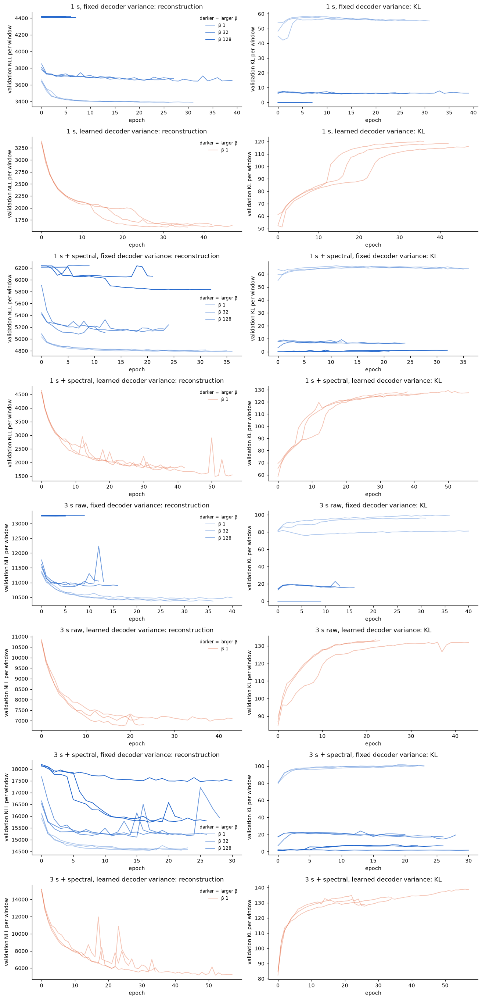

In [3]:
if HAVE_RUNS:
    vr.plot_curves(runs, found)

## 3. How much of the code each VAE uses

Active dimensions and KL against β, per input and decoder variance (compare notebook 02 for the conv VAE).

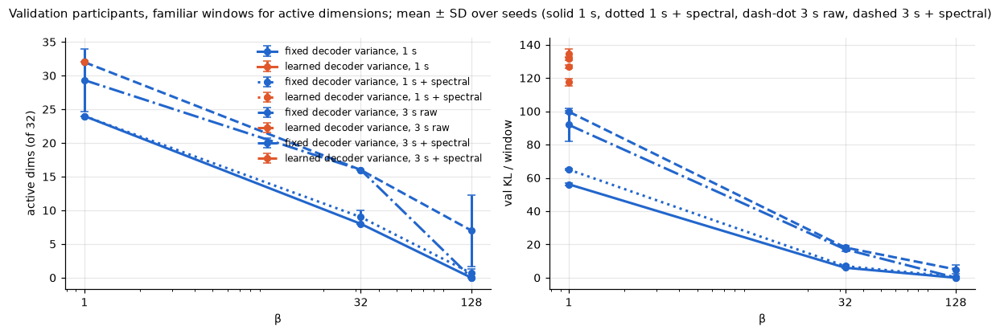

In [4]:
if HAVE_RUNS:
    vr.plot_active_and_kl(per_seed, FIG_DIR / f'{NB}_{TAG}_active_kl.png')

### 3.1 KL per latent dimension

Mean KL of each dimension over the validation participants' windows (seed 0): which of the 32 dimensions carry
information, and whether the same ones survive as β grows. Columns are the 4 filters × 8 time steps.

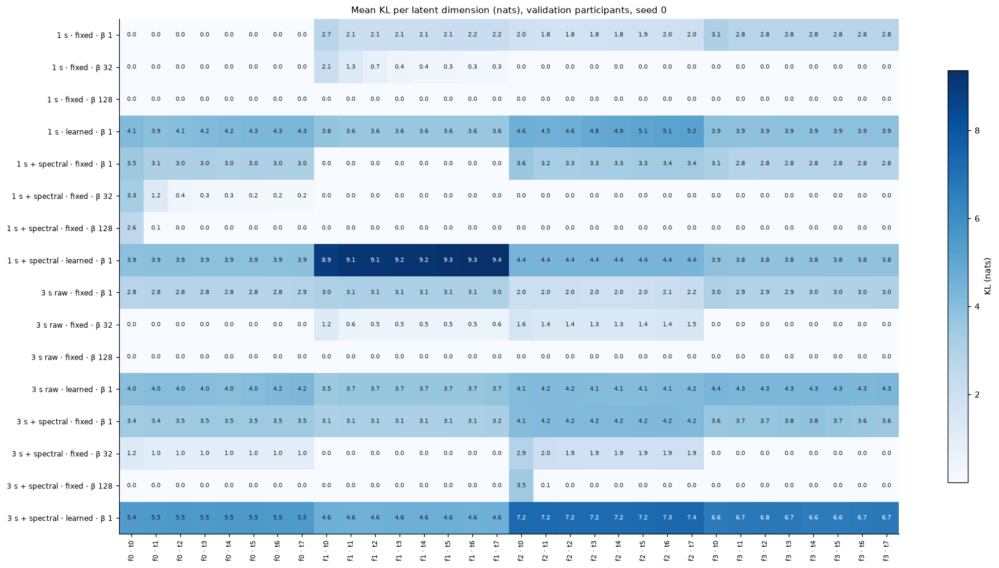

In [5]:
if HAVE_RUNS:
    shown = found[found['seed'] == SHOWN_SEED]
    grid = pd.DataFrame({vr.get_cell_label(r.inputs, r.decoder_variance, r.beta): vr.get_kl_per_dim(runs[r.run]['z'], runs[r.run]['logvar'])
                         for r in shown.itertuples()}).T
    grid.columns = [f'f{u // 8} · t{u % 8}' for u in grid.columns]
    vr.plot_heatmap(grid, f'Mean KL per latent dimension (nats), validation participants, seed {SHOWN_SEED}', 'KL (nats)', '{:.1f}')

## 4. The learned decoder variance

Decoder standard deviation per input channel, in standardized units (1 = the channel's training SD), for the
learned-variance runs: which channels the decoder reconstructs confidently. The fixed-variance runs have 1 everywhere.

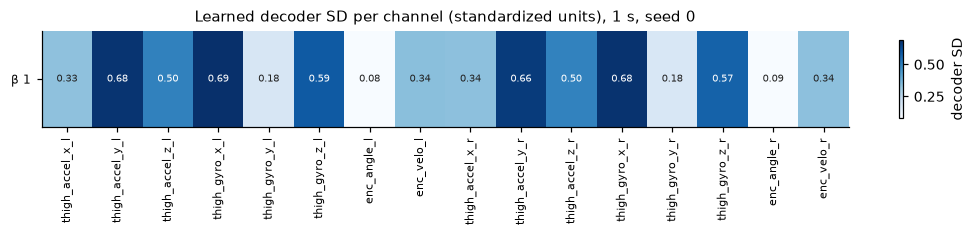

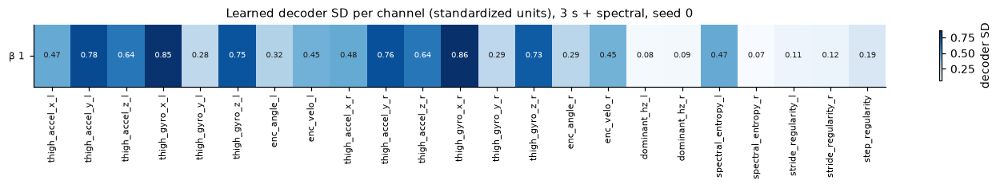

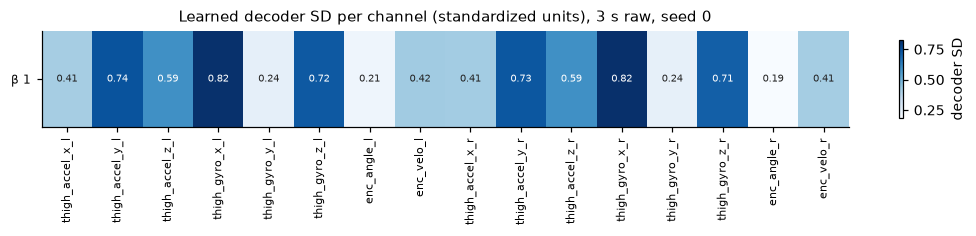

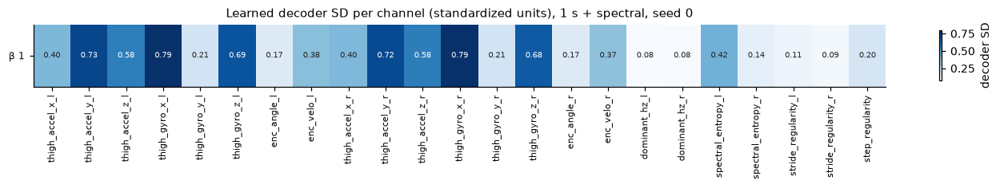

In [6]:
if HAVE_RUNS:
    for inputs, spec in meta['inputs'].items():
        learned = found[(found['decoder_variance'] == 'learned') & (found['seed'] == SHOWN_SEED) & (found['inputs'] == inputs)]
        if learned.empty:
            continue
        channel_names = meta['channels'] + list(spec['features'])
        sigma = pd.DataFrame({f'β {r.beta:g}': runs[r.run]['summary']['decoder_sigma'] for r in learned.itertuples()}, index = channel_names).T
        vr.plot_heatmap(sigma, f'Learned decoder SD per channel (standardized units), {vr.INPUT_SHORT[inputs]}, seed {SHOWN_SEED}', 'decoder SD',
                        '{:.2f}', save = FIG_DIR / f'{NB}_{TAG}_decoder_sigma_{inputs}.png')


## 5. Posterior width by task

Median over each task's validation windows of the mean posterior variance across the run's active dimensions (seed 0).
With the variance fixed, the Science Robotics study found this flat across tasks; this shows whether it still is.
Descriptive only: how well it separates unfamiliar movement is a score, and is notebook 05's.

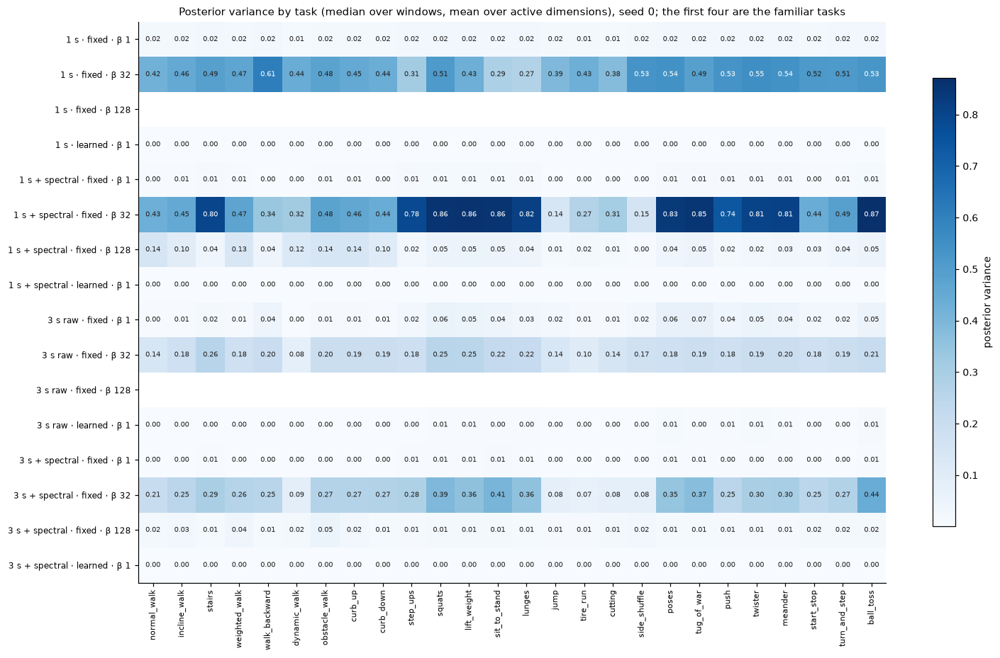

In [7]:
if HAVE_RUNS:
    tasks = list(nt.ID_SAFE_TASKS) + [t for ts in nt.TASK_FAMILIES.values() for t in ts if t not in nt.ID_SAFE_TASKS]
    widths = {}
    for r in shown.itertuples():
        run = runs[r.run]
        familiar = (run['labels']['controller_class'].astype(str) == 'ID-safe').to_numpy()
        widths[vr.get_cell_label(r.inputs, r.decoder_variance, r.beta)] = vr.get_width_by_task(run['labels'], run['logvar'],
                                                                            vr.get_active(run['logvar'], familiar))
    width = pd.DataFrame(widths).T.reindex(columns = tasks)
    vr.plot_heatmap(width, f'Posterior variance by task (median over windows, mean over active dimensions), seed {SHOWN_SEED}; '
                    'the first four are the familiar tasks', 'posterior variance', '{:.2f}')

## 6. Latent maps

Posterior means of up to 250 validation windows per task (the same windows for every run), on the run's active
dimensions, in the three views of notebook 01 (the highest-variance dimensions, PCA, UMAP), coloured by task family and
by controller class. One row per β for each input and decoder variance, seed 0. The windows are
those every run exported, so 1 s and 3 s models are drawn on the same windows.

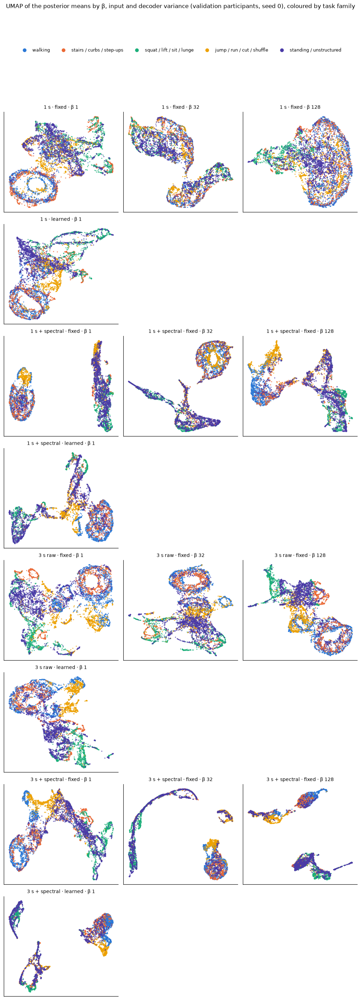

6,500 validation windows, 26 tasks, participants ['BT09', 'BT12', 'BT13', 'BT21']


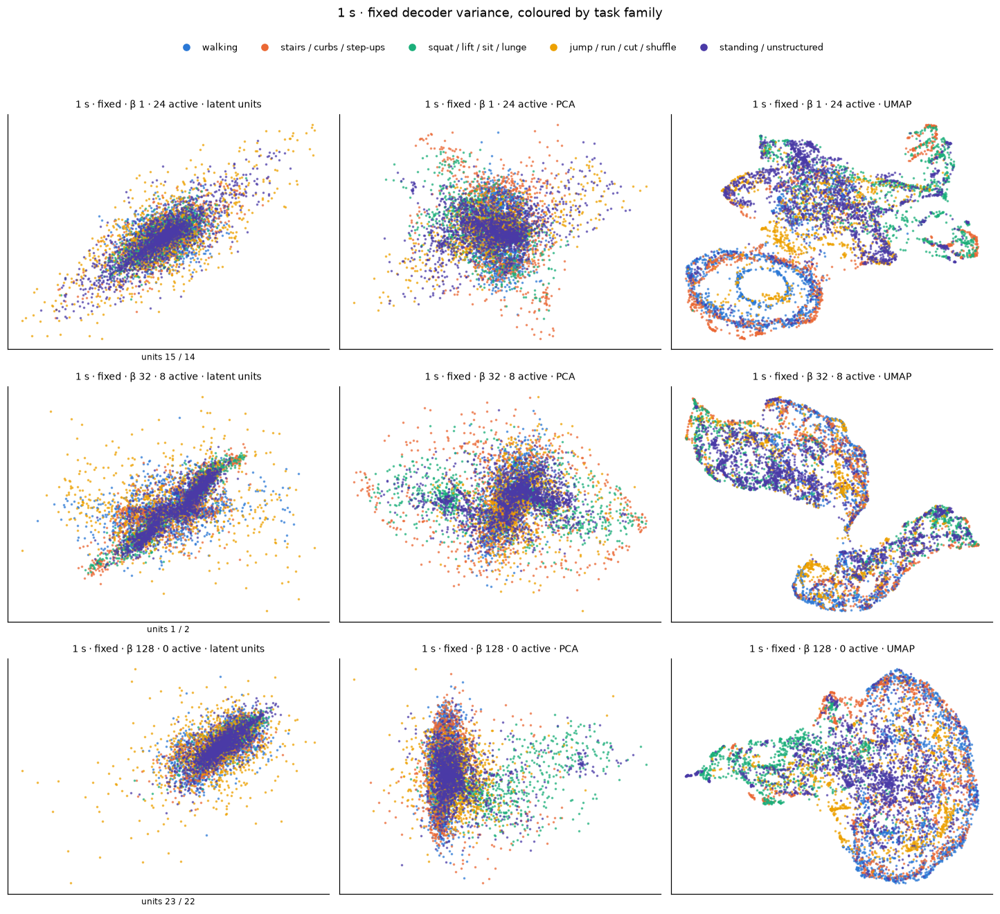

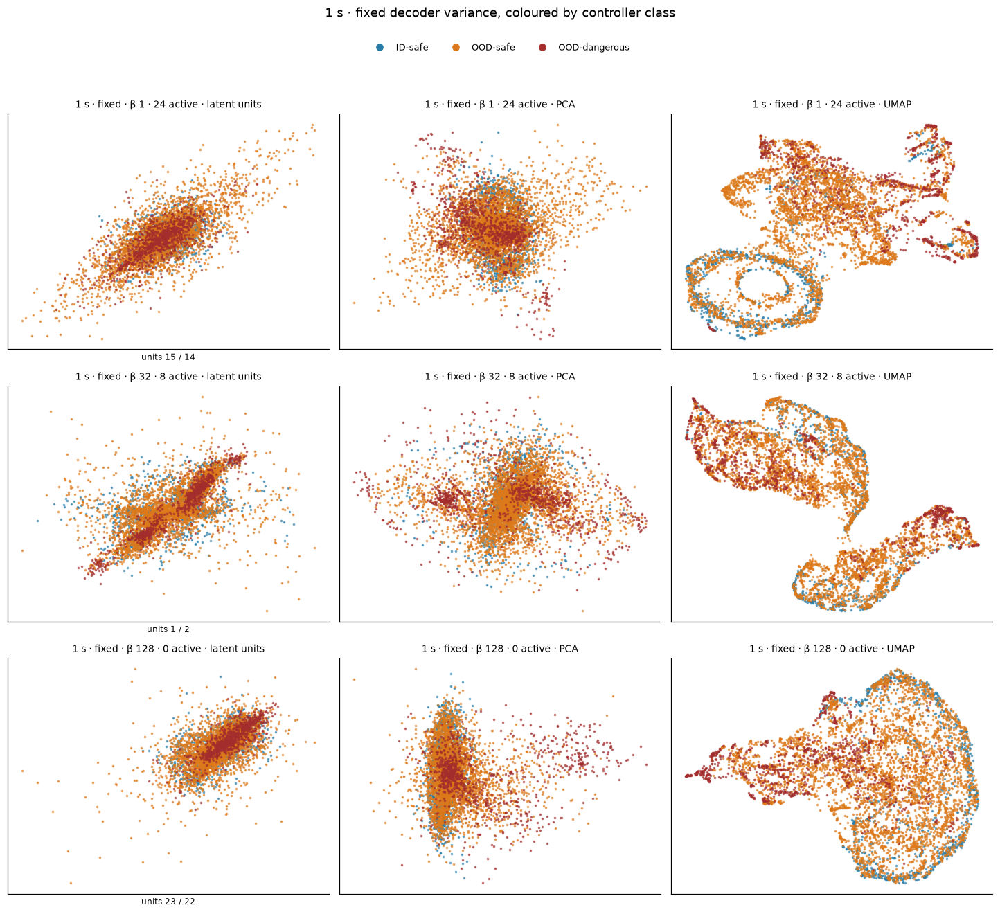

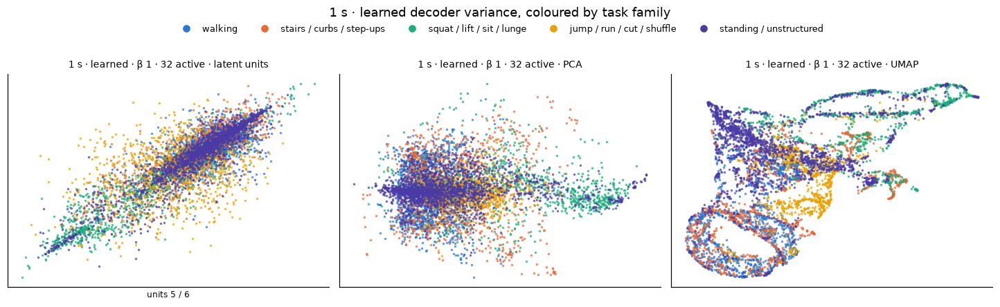

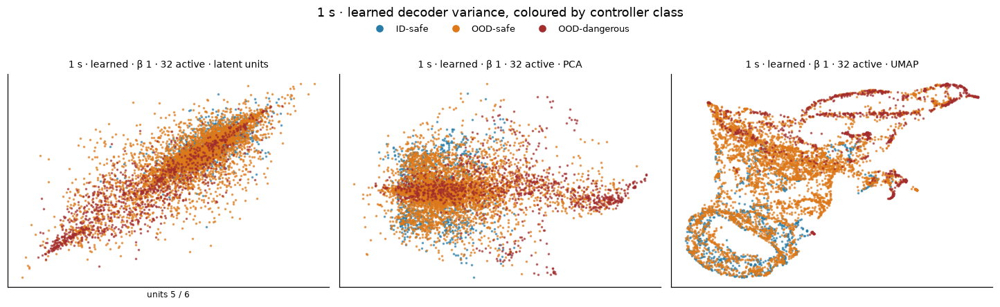

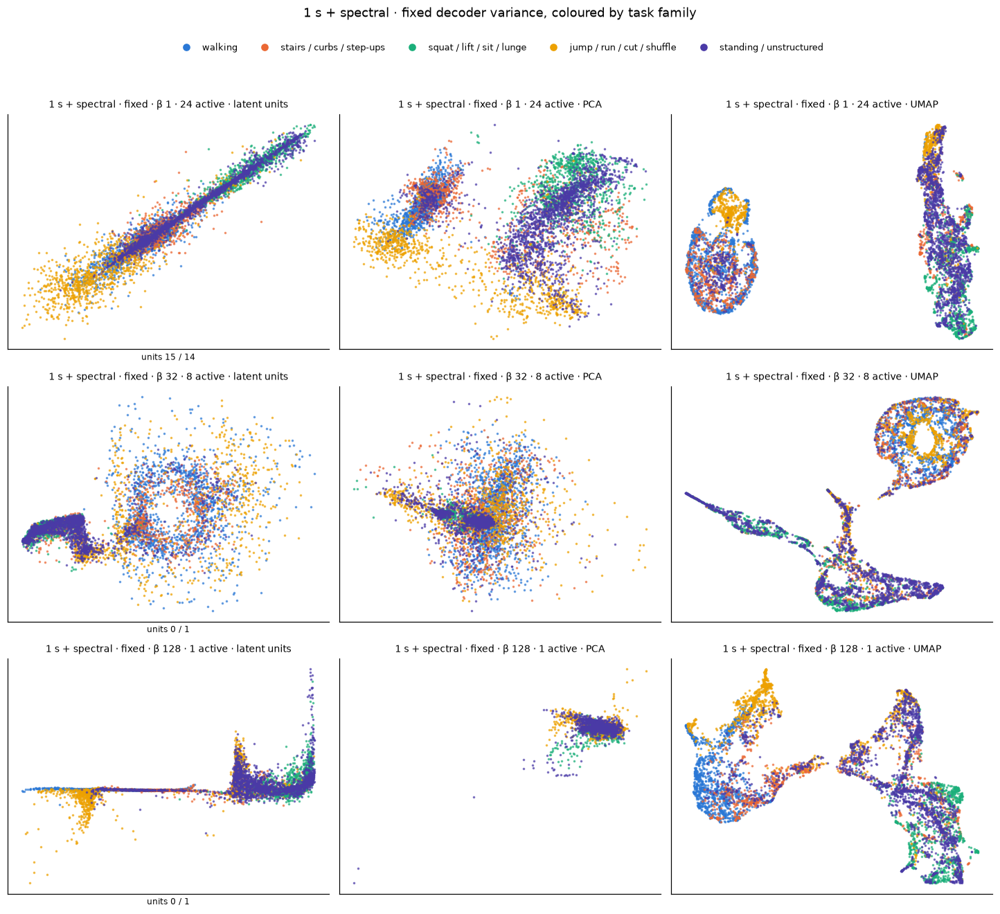

...

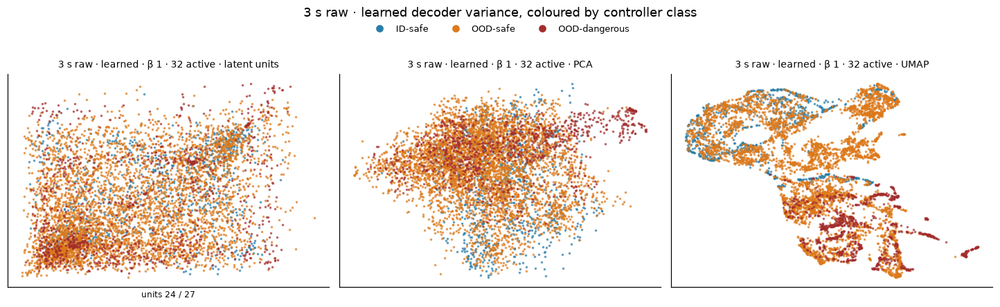

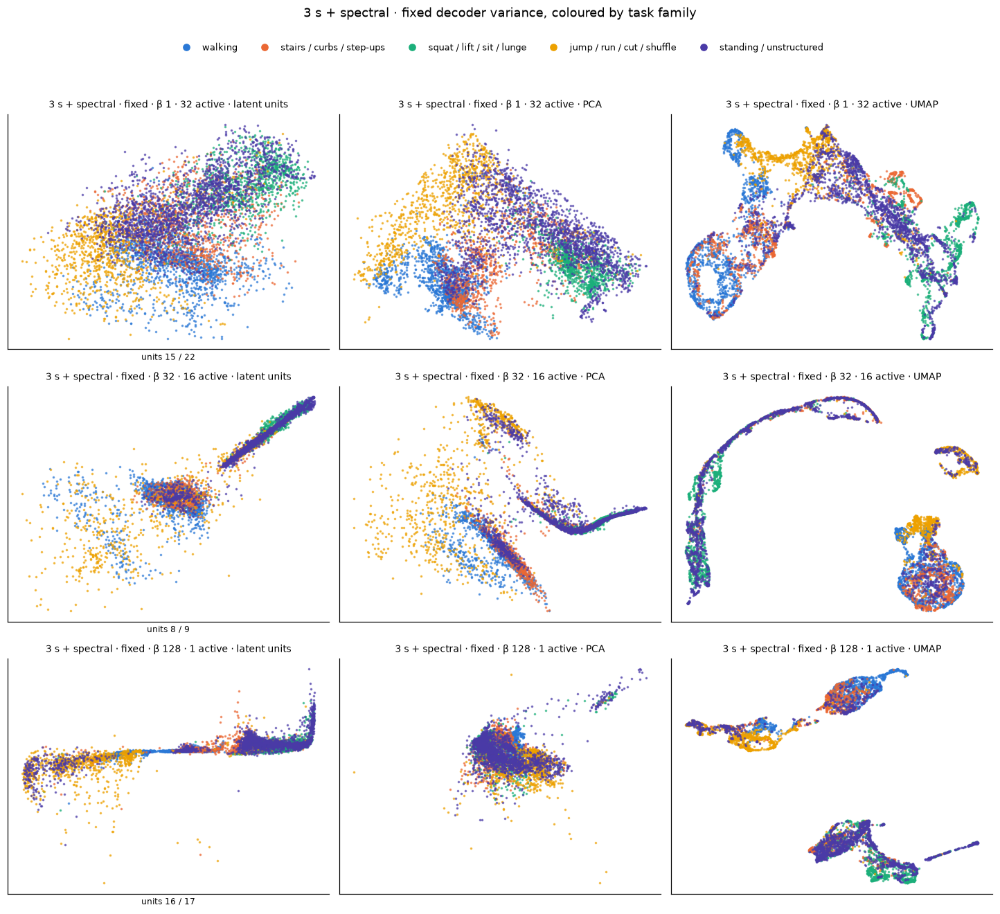

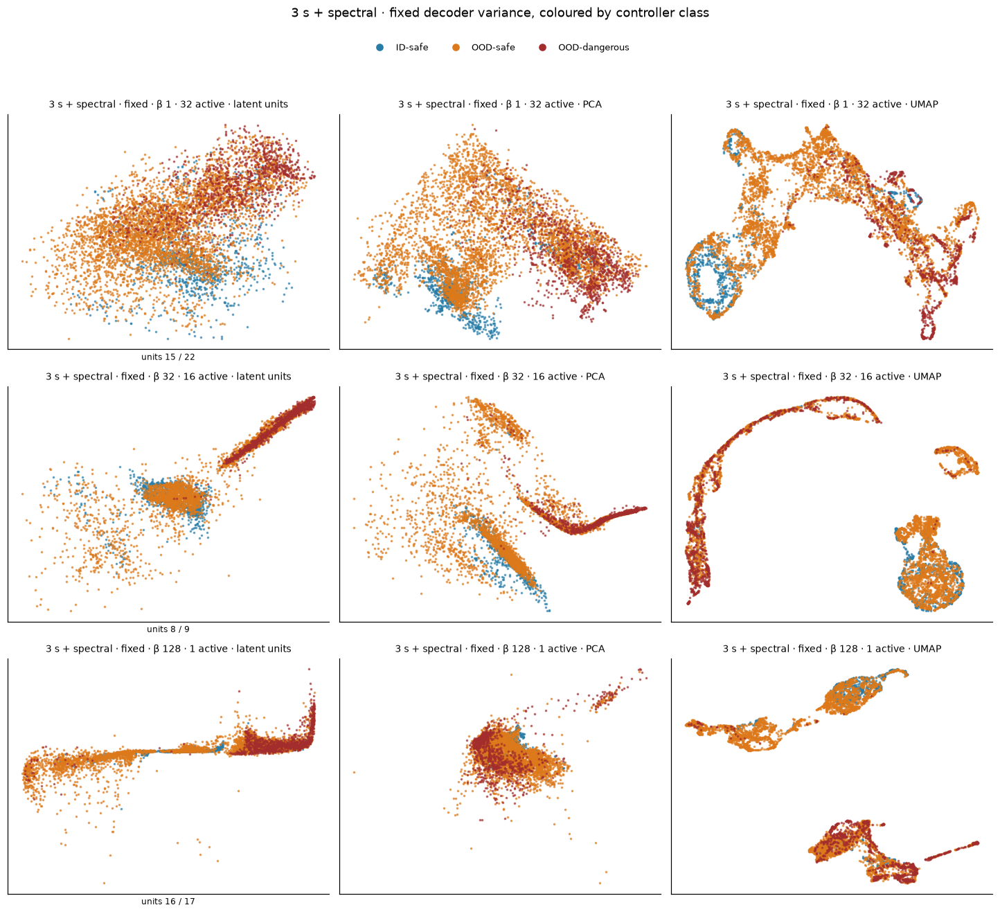

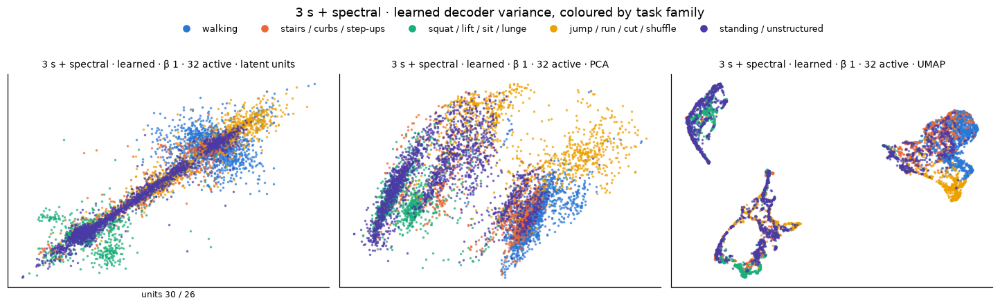

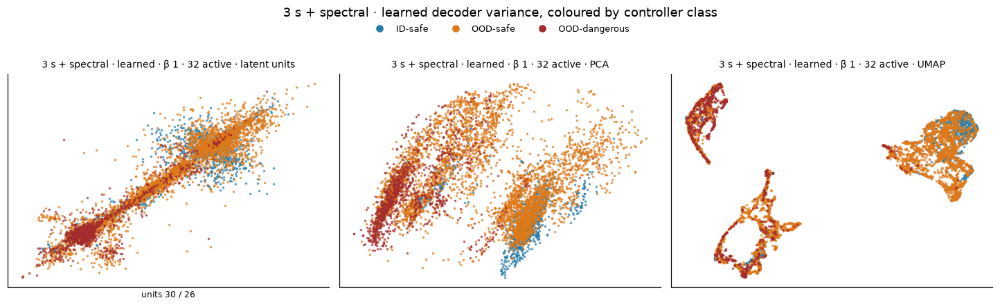

In [8]:
if HAVE_RUNS:
    base = shown.sort_values('inputs', ascending = False).iloc[0]                 # a 3 s run if any: its windows exist in every run
    first = runs[base.run]['labels']
    pick = lv.get_balanced_sample(first, 250, np.random.default_rng(0))
    labels = first.iloc[pick].reset_index(drop = True)
    views, actives = {}, {}
    for r in shown.itertuples():
        run = runs[r.run]
        z = lv.get_aligned_z({'labels': run['labels'], 'z': run['z']}, labels)                  # (N, 32), same windows
        familiar = (run['labels']['controller_class'].astype(str) == 'ID-safe').to_numpy()
        active = vr.get_active(run['logvar'], familiar)
        key = vr.get_cell_label(r.inputs, r.decoder_variance, r.beta)
        views[key], actives[key] = lv.get_views(z[:, active] if active.sum() >= 3 else z, VIEW_CACHE), int(active.sum())
    keyed = {(' · '.join(k.split(' · ')[:2]), float(k.split(' · ')[2].removeprefix('β '))): v for k, v in views.items()}
    vr.plot_umap_by_beta(keyed, labels, 'family', lv.FAMILY_C, lv.BACKGROUND, 'UMAP of the posterior means by β, input and decoder variance '
                         f'(validation participants, seed {SHOWN_SEED}), coloured by task family', FIG_DIR / f'{NB}_{TAG}_umap_by_beta.png')
    print(f'{len(labels):,} validation windows, {labels.task.nunique()} tasks, participants {sorted(labels.subject.astype(str).unique())}')
    for group in dict.fromkeys(k[0] for k in keyed):
        part = {f'{k} · {actives[k]} active': v for k, v in views.items() if k.startswith(group + ' ·')}
        lv.plot_lens_grid(part, labels, 'family', lv.FAMILY_C, f'{group} decoder variance, coloured by task family')
        lv.plot_lens_grid(part, labels, 'controller_class', lv.CLASS_C, f'{group} decoder variance, coloured by controller class')


## 7. Interactive 3-D: the best fixed- and learned-variance LSTM-VAE

The two cells drawn are chosen in notebook 05 (section 7.2's rule): for each decoder variance, the cell (β and input)
whose best native score has the highest validation AUROC for unfamiliar against familiar windows. Seed 0, the windows of
section 6 (up to 80 per task here), in 3-D; the dropdown switches view and lens. Besides task, family, controller class and
direction, a **KL quartile** lens colours each window by its KL in that run (light = lowest), because at high β the KL
is that model's novelty signal. Standalone copies are saved in `interactive/`.

In [9]:
import re

RESULTS = Path.cwd() / 'results' / '05_native_scores.csv'                    # written by notebook 05, section 7.2
INTERACTIVE = Path.cwd() / 'interactive'
CONFIG_3D = {'scrollZoom': True, 'displaylogo': False}
KL_C = {'1 lowest': '#c6dbef', '2': '#6baed6', '3': '#2171b5', '4 highest': '#08306b'}   # sequential: one hue, light to dark
if HAVE_RUNS and RESULTS.exists():
    native = pd.read_csv(RESULTS)
    native = native[native['family'] == 'vae']
    val_best = native.groupby(['model', 'score'])['val AUROC, unfamiliar vs familiar'].mean().groupby('model').max()
    found['model'] = [ns.get_model_label(r.config, r.stem) for r in found.itertuples()]
    STYLES = lv.get_task_styles(nt.TASK_FAMILIES)
    lenses = {'task': ('task', {t: STYLES[t]['family'] for ts in nt.TASK_FAMILIES.values() for t in ts}),
              'family': ('family', lv.FAMILY_C), 'controller class': ('controller_class', lv.CLASS_C),
              'direction': ('direction', lv.DIRECTION_C), 'KL quartile': ('kl_quartile', KL_C)}
    rng3 = np.random.default_rng(1)
    show = np.sort(np.concatenate([rng3.choice(np.flatnonzero(labels['task'].astype(str).to_numpy() == t),
                                               min(80, int((labels['task'] == t).sum())), replace = False)
                                    for t in labels['task'].astype(str).unique()]))
    for variance in ('fixed', 'learned'):
        candidates = val_best[[m for m in val_best.index if f'{variance} variance' in m and m.startswith(MODEL_PREFIX)]]
        if candidates.empty:
            print(f'no scored {variance}-variance runs of this architecture in {RESULTS.name} yet: run notebook 05 first')
            continue
        model = candidates.idxmax()
        r = found[(found['model'] == model) & (found['seed'] == SHOWN_SEED)].iloc[0]
        run = runs[r.run]
        idx = run['labels'][['rec', 'end']].reset_index().merge(labels[['rec', 'end']], on = ['rec', 'end'], how = 'right')['index'].to_numpy()
        lab3 = labels.copy()
        lab3['kl_quartile'] = pd.qcut(run['kl'][idx], 4, labels = list(KL_C)).astype(str)
        familiar = (run['labels']['controller_class'].astype(str) == 'ID-safe').to_numpy()
        active = vr.get_active(run['logvar'], familiar)
        z = run['z'][idx]
        v3 = lv.get_views(z[:, active] if active.sum() >= 3 else z, VIEW_CACHE)
        name = f'{model} (validation AUROC {candidates.max():.3f})'
        fig = lv.build_3d({name: {k: v[show] for k, v in v3.items() if k != 'units'}}, lab3.iloc[show].reset_index(drop = True),
                          lenses, {t: s['symbol'] for t, s in STYLES.items()}, name)
        INTERACTIVE.mkdir(exist_ok = True)
        path = INTERACTIVE / f'{TAG}_best_{variance}_3d.html'
        fig.write_html(path, include_plotlyjs = 'cdn', config = CONFIG_3D)
        fig.show(config = CONFIG_3D)
        print(f'best {variance}-variance cell: {model}; standalone copy {path.relative_to(REPO)}')
elif HAVE_RUNS:
    print('Run notebook 05 first: it writes results/05_native_scores.csv, which picks the cells shown here.')

best fixed-variance cell: LSTM-VAE · β 1 · fixed variance · 3 s raw; standalone copy notebooks/nature/model_exploration/onboard/interactive/lstm_vae_best_fixed_3d.html


best learned-variance cell: LSTM-VAE · β 1 · learned variance · 3 s raw; standalone copy notebooks/nature/model_exploration/onboard/interactive/lstm_vae_best_learned_3d.html


## 8. What this shows

The latent spaces only; detection is notebook 05's (section 9 there compares the six model types on the four inputs, and
this model on 3 s raw is the best detector found: test AUROC 0.963 for unfamiliar and 0.993 for OOD-dangerous windows).

- **At β 1 the LSTM-VAE leaves part of its code idle on 1 s windows.** With fixed variance 24 of 32 dimensions are
  active on 1 s and 1 s + spectral input (one filter unused), 29 ± 5 on 3 s raw and all 32 on 3 s + spectral; the
  learned variance uses all 32 on every input (1, 3). Its KL is close to the conv VAE's (56 against 60 nats per window on
  1 s, 92 against 81 on 3 s raw).
- **At β 128 its posterior collapses on raw input.** On 1 s and 3 s raw windows the KL is zero in all three seeds, no
  dimension is active, and the reconstruction error (0.92, against 0.28 at β 1) is that of an output that ignores the
  window; the best epoch is one of the first five. With the spectral features it nearly collapses on 1 s (0.5 nats per
  familiar window, 0.7 active dimensions) and keeps 7 ± 5 dimensions on 3 s. The non-autoregressive decoder keeps the KL
  well away from zero at β 1 and 32, but it does not stop a large β from pushing the posterior onto the prior; the conv
  VAE keeps one filter at β 128 on every input. KL warm-up is the usual remedy if a high-β sequence VAE is ever needed;
  notebook 05 chose β 1 on every input, and its β 128 entries for this model come from an empty or nearly empty code.
- **The 3 s raw latent, the best detector, is the most finely structured map here.** Its UMAP (6) gives most tasks a
  loop or cluster of their own: rings for walking and stairs, the jumping-and-running family apart, squatting and lifting
  on their own arm, the standing tasks in a central cloud.
- **It is also the latent whose posterior width follows familiarity most clearly.** In that cell (β 1, fixed) the
  median posterior variance is 0.00 to 0.02 on the four familiar tasks and on the near-familiar ones (obstacle and
  dynamic walking, curbs), and 0.04 to 0.07 on walking backwards, squats, lifting, sit-to-stand, poses, tug of war, push,
  twister, meander and the ball toss (5). Vigorous tasks stay narrow (jumping, running and cutting, 0.01 to 0.02).
  Consistent with this, its posterior variance scores 0.897 in notebook 05 (higher = unfamiliar), where the conv VAE's
  reaches 0.70 to 0.80 and mostly points down. The wide tasks are the quiet, posture-driven ones that LOF on the
  autoencoder latents flagged least (notebook 05, section 4). At β 32 this model, like the others, instead gives the
  vigorous tasks the narrowest posteriors.
- **Its raw latents are the least like the other models'.** On 3 s raw the plain, Gaussian-NLL, conv and Transformer
  latents resemble one another (linear CKA 0.57 to 0.71), while this one shares 0.27 to 0.47 with each of them (notebook
  05, section 9.4): reading the window in time order gives a different code, and the better detector.
- **The spectral features split its latent into islands.** With them the maps often break into disconnected pieces (6),
  and a linear readout of the posterior means picks out the fifth of windows with no detectable rhythm (spectral
  features 0) almost perfectly: AUROC 0.97 on the 1 s + spectral and 3 s + spectral latents, against 0.63 and 0.82 on the
  raw ones (β 1, fixed, seed 0; the conv and Transformer VAEs give 1.00 against 0.79 and 0.77). Every spectral latent
  encodes whether the person is moving rhythmically, a likely reason the spectral latents of all architectures resemble
  one another (notebook 05, section 9.4).
- **The learned decoder variance matches the conv VAE's.** The hip encoder angle (0.08 to 0.32 of its SD) and the
  sagittal thigh gyro (0.18 to 0.29) are reconstructed most precisely, the thigh gyro's x axis and the accelerometer's y
  axis least (0.68 to 0.86), the 3 s decoders a little looser than the 1 s ones (4).
- **The 3-D pages** (7): the best fixed-variance cell is β 1 on 3 s raw, the study's best detector, and the best
  learned-variance cell is β 1 on 3 s raw as well.